# Option 3 fsaverage cortical-column QC

This notebook audits the current `O3-Coordinate` workflow for subject
`D0086` on the `fsaverage` target. It runs both hemispheres when the
existing outputs are available.

The notebook reads the saved O3 arrays and supporting FreeSurfer files.
It does not modify or rerun the O3 generation pipeline, does not run
fsaverage6, and does not compare O3 with O2-FS.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display


PROJECT_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis"
)
sys.path.insert(0, str(PROJECT_ROOT / "notebooks"))

from qc_o3_fsaverage_helpers import run_qc


CONFIG = {
    "subject_id": "D0086",
    "hemispheres": ["lh", "rh"],
    "target_template": "fsaverage",
    "o3_output_root": (
        "/mnt/newStor/paros/paros_WORK/xintong/results/"
        "o3_coordinate_profiles"
    ),
    "freesurfer_subjects_dir": "/home/apps/freesurfer/subjects",
    "native_subjects_root": (
        "/mnt/newStor/paros/paros_WORK/xintong/data/processed/"
        "t1_freesurfer"
    ),
    "fsaverage_surface_paths": {
        "lh": "/home/apps/freesurfer/subjects/fsaverage/surf/lh.white",
        "rh": "/home/apps/freesurfer/subjects/fsaverage/surf/rh.white",
    },
    "md_volume_path": (
        "/mnt/newStor/paros/paros_WORK/xintong/data/processed/"
        "dwi/D0086/D0086_md.nii.gz"
    ),
    "registration_path": (
        "/mnt/newStor/paros/paros_WORK/xintong/results/column_analysis/"
        "D0086/registration/D0086_DWI2T1.dat"
    ),
    "qc_output_root": "/mnt/newStor/paros/paros_WORK/xintong/results/o3_qc",
    "depths": np.linspace(0.0, 1.0, 21),
    "expected_fsaverage_vertices": 163842,
    "weight_tol": 1e-6,
    "coord_tol_mm": 1e-5,
    "min_valid_profile_fraction": 0.99,
    "min_in_bounds_fraction": 0.99,
    "round_trip_sample_size": 10000,
    "random_seed": 20261005,
}

CONFIG

{'subject_id': 'D0086',
 'hemispheres': ['lh', 'rh'],
 'target_template': 'fsaverage',
 'o3_output_root': '/mnt/newStor/paros/paros_WORK/xintong/results/o3_coordinate_profiles',
 'freesurfer_subjects_dir': '/home/apps/freesurfer/subjects',
 'native_subjects_root': '/mnt/newStor/paros/paros_WORK/xintong/data/processed/t1_freesurfer',
 'fsaverage_surface_paths': {'lh': '/home/apps/freesurfer/subjects/fsaverage/surf/lh.white',
  'rh': '/home/apps/freesurfer/subjects/fsaverage/surf/rh.white'},
 'md_volume_path': '/mnt/newStor/paros/paros_WORK/xintong/data/processed/dwi/D0086/D0086_md.nii.gz',
 'registration_path': '/mnt/newStor/paros/paros_WORK/xintong/results/column_analysis/D0086/registration/D0086_DWI2T1.dat',
 'qc_output_root': '/mnt/newStor/paros/paros_WORK/xintong/results/o3_qc',
 'depths': array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 'expected_fsaverage_vertices': 163842,
 'weight_tol'

## Provenance and coordinate conventions

The O3 NPZ files contain the following relevant arrays:

- `target_vertex_id`: fsaverage vertex IDs;
- `source_face_id`, `source_vertex_ids`, `barycentric_weights`: native
  surface mapping provenance;
- `white_anchor`, `pial_anchor`, `native_coordinates`: FreeSurfer
  surface RAS coordinates in subject T1 space;
- `dwi_voxel_coordinates`: 0-based DWI voxel coordinates after the
  legacy one-based transform output is reduced by one;
- `md_profiles`: target-vertex by 21-depth MD values.

Native and template `aparc.annot` files and native FreeSurfer thickness
files are available for both D0086 hemispheres and are used below.

In [2]:
from datetime import datetime


def file_record(path):
    path = Path(path)
    return {
        "path": str(path),
        "exists": path.is_file(),
        "modified": (
            datetime.fromtimestamp(path.stat().st_mtime).isoformat()
            if path.is_file()
            else None
        ),
    }


provenance_paths = []
for hemisphere in CONFIG["hemispheres"]:
    o3_path = (
        Path(CONFIG["o3_output_root"])
        / CONFIG["subject_id"]
        / "fsaverage"
        / "o3_coordinate"
        / f"{CONFIG['subject_id']}_{hemisphere}_profiles.npz"
    )
    provenance_paths.extend(
        [
            o3_path,
            o3_path.with_suffix(".qc.json"),
            Path(CONFIG["fsaverage_surface_paths"][hemisphere]),
            Path(CONFIG["native_subjects_root"])
            / CONFIG["subject_id"]
            / "surf"
            / f"{hemisphere}.white",
            Path(CONFIG["native_subjects_root"])
            / CONFIG["subject_id"]
            / "surf"
            / f"{hemisphere}.pial",
            Path(CONFIG["native_subjects_root"])
            / CONFIG["subject_id"]
            / "surf"
            / f"{hemisphere}.thickness",
            Path(CONFIG["native_subjects_root"])
            / CONFIG["subject_id"]
            / "label"
            / f"{hemisphere}.aparc.annot",
            Path(CONFIG["freesurfer_subjects_dir"])
            / "fsaverage"
            / "label"
            / f"{hemisphere}.aparc.annot",
        ]
    )
provenance_paths.extend(
    [Path(CONFIG["md_volume_path"]), Path(CONFIG["registration_path"])]
)
provenance = pd.DataFrame(file_record(path) for path in provenance_paths)
display(provenance)
if not provenance.exists.all():
    missing = provenance.loc[~provenance.exists, "path"].tolist()
    raise FileNotFoundError(f"Missing required QC inputs: {missing}")

,path,exists,modified
0,/mnt/newStor/paros/paros_WORK/xintong/results/...,True,2026-10-02T14:43:35.476503
1,/mnt/newStor/paros/paros_WORK/xintong/results/...,True,2026-10-02T14:43:35.628513
2,/home/apps/freesurfer/subjects/fsaverage/surf/...,True,2018-07-19T12:50:47
3,/mnt/newStor/paros/paros_WORK/xintong/data/pro...,True,2026-09-08T20:01:24.798610
4,/mnt/newStor/paros/paros_WORK/xintong/data/pro...,True,2026-09-08T20:06:18.671345
5,/mnt/newStor/paros/paros_WORK/xintong/data/pro...,True,2026-09-08T20:09:14.999586
6,/mnt/newStor/paros/paros_WORK/xintong/data/pro...,True,2026-09-08T19:58:48.665656
7,/home/apps/freesurfer/subjects/fsaverage/label...,True,2010-12-30T17:35:38
8,/mnt/newStor/paros/paros_WORK/xintong/results/...,True,2026-10-02T14:43:44.180058
9,/mnt/newStor/paros/paros_WORK/xintong/results/...,True,2026-10-02T14:43:44.327068


## Execute QC

This cell performs the complete D0086 left/right fsaverage QC and
writes subject-specific tables, overlays, figures, and a compact JSON
metrics file under `results/o3_qc/D0086/`.

In [3]:
QC_RESULTS = run_qc(CONFIG)
display(QC_RESULTS["summary"])

,category,metric,value,threshold,status,hemisphere
0,target_vertex_completeness,loaded_vertices,1.638420e+05,163842,PASS,lh
1,target_vertex_completeness,duplicate_vertex_ids,0.000000e+00,0,PASS,lh
2,mapping,mapping_success_pct,1.000000e+02,99.0,PASS,lh
3,barycentric_weights,max_abs_weight_sum_error,2.220446e-16,0.000001,PASS,lh
4,geometry,coordinate_reconstruction_max_mm,0.000000e+00,0.00001,PASS,lh
5,geometry,zero_length_column_count,1.249100e+04,0,FAIL,lh
6,coordinates,finite_t1_pct,1.000000e+02,99.0,PASS,lh
7,coordinates,dwi_in_bounds_pct,1.000000e+02,99.0,PASS,lh
8,md_profile,complete_finite_profile_pct,1.000000e+02,99.0,PASS,lh
9,region_boundary,mixed_label_triangle_pct,3.888502e+00,descriptive,WARNING,lh


In [4]:
output_root = Path(QC_RESULTS["output_root"])
summary = pd.read_csv(
    output_root / "D0086_o3_qc_summary_all_hemispheres.csv"
)
display(summary)

depth_tables = []
for hemisphere in CONFIG["hemispheres"]:
    md_table = pd.read_csv(
        output_root
        / "tables"
        / f"D0086_{hemisphere}_md_depth_summary.csv"
    )
    coordinate_table = pd.read_csv(
        output_root
        / "tables"
        / f"D0086_{hemisphere}_coordinate_depth_qc.csv"
    )
    depth_tables.append(
        md_table.assign(hemisphere=hemisphere).merge(
            coordinate_table.assign(hemisphere=hemisphere),
            on=["hemisphere", "depth"],
        )
    )
depth_summary = pd.concat(depth_tables, ignore_index=True)
display(depth_summary)

,category,metric,value,threshold,status,hemisphere
0,target_vertex_completeness,loaded_vertices,1.638420e+05,163842,PASS,lh
1,target_vertex_completeness,duplicate_vertex_ids,0.000000e+00,0,PASS,lh
2,mapping,mapping_success_pct,1.000000e+02,99.0,PASS,lh
3,barycentric_weights,max_abs_weight_sum_error,2.220446e-16,1e-06,PASS,lh
4,geometry,coordinate_reconstruction_max_mm,0.000000e+00,1e-05,PASS,lh
5,geometry,zero_length_column_count,1.249100e+04,0,FAIL,lh
6,coordinates,finite_t1_pct,1.000000e+02,99.0,PASS,lh
7,coordinates,dwi_in_bounds_pct,1.000000e+02,99.0,PASS,lh
8,md_profile,complete_finite_profile_pct,1.000000e+02,99.0,PASS,lh
9,region_boundary,mixed_label_triangle_pct,3.888502e+00,descriptive,WARNING,lh


,depth,finite_pct,nan_pct,zero_pct,median,q25,q75,iqr,p01,p99,hemisphere,finite_t1_pct,finite_dwi_pct,in_bounds_pct,out_of_bounds_pct
0,0.00,100.0,0.0,0.000000,0.000717,0.000665,0.000778,0.000114,0.000492,0.001526,lh,100.0,100.0,100.0,0.0
1,0.05,100.0,0.0,0.000000,0.000716,0.000664,0.000778,0.000114,0.000493,0.001529,lh,100.0,100.0,100.0,0.0
2,0.10,100.0,0.0,0.000000,0.000715,0.000663,0.000778,0.000115,0.000495,0.001533,lh,100.0,100.0,100.0,0.0
3,0.15,100.0,0.0,0.000000,0.000715,0.000662,0.000779,0.000117,0.000494,0.001538,lh,100.0,100.0,100.0,0.0
4,0.20,100.0,0.0,0.000000,0.000715,0.000662,0.000781,0.000119,0.000495,0.001545,lh,100.0,100.0,100.0,0.0
5,0.25,100.0,0.0,0.000000,0.000715,0.000662,0.000784,0.000122,0.000496,0.001554,lh,100.0,100.0,100.0,0.0
6,0.30,100.0,0.0,0.000000,0.000716,0.000663,0.000789,0.000127,0.000496,0.001563,lh,100.0,100.0,100.0,0.0
7,0.35,100.0,0.0,0.000000,0.000718,0.000663,0.000796,0.000133,0.000494,0.001575,lh,100.0,100.0,100.0,0.0
8,0.40,100.0,0.0,0.000000,0.000722,0.000664,0.000806,0.000142,0.000491,0.001588,lh,100.0,100.0,100.0,0.0
9,0.45,100.0,0.0,0.000000,0.000727,0.000665,0.000818,0.000152,0.000487,0.001605,lh,100.0,100.0,100.0,0.0


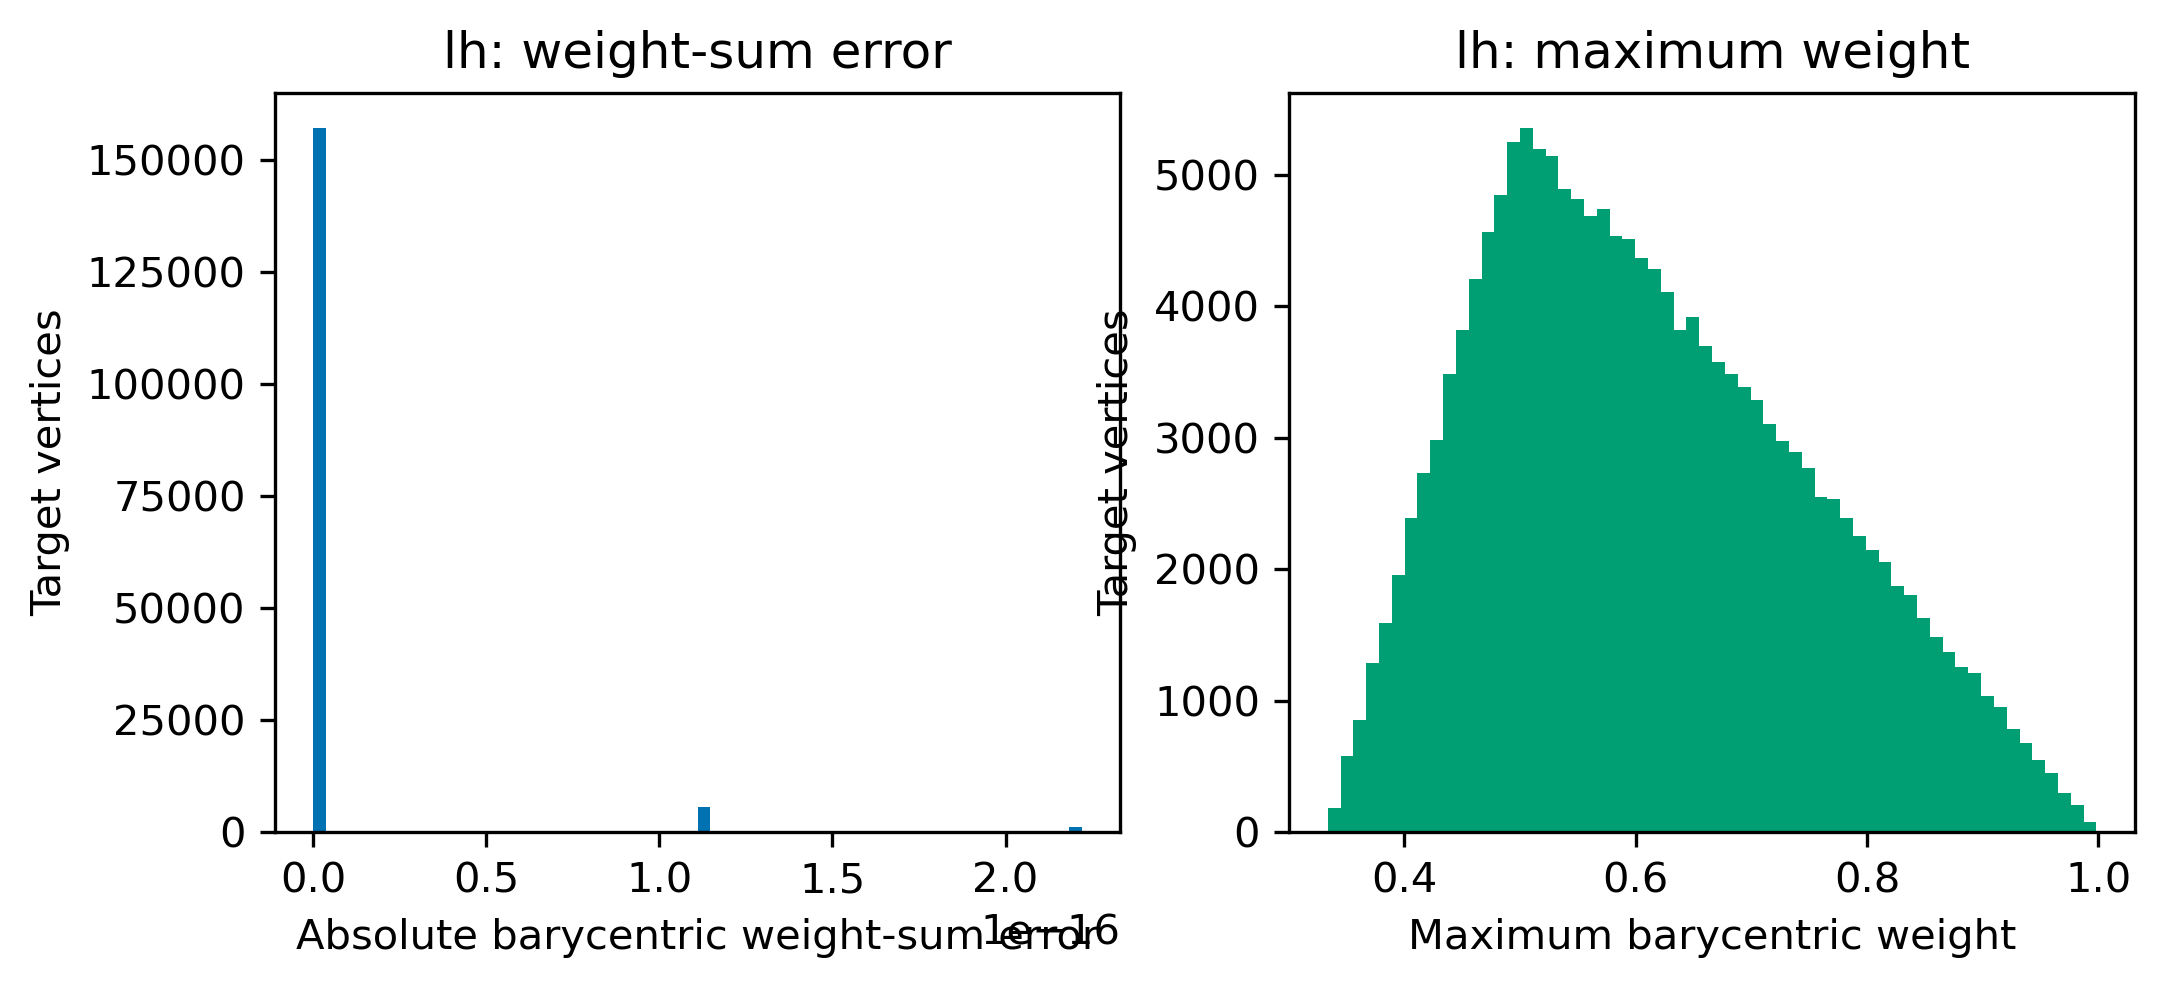

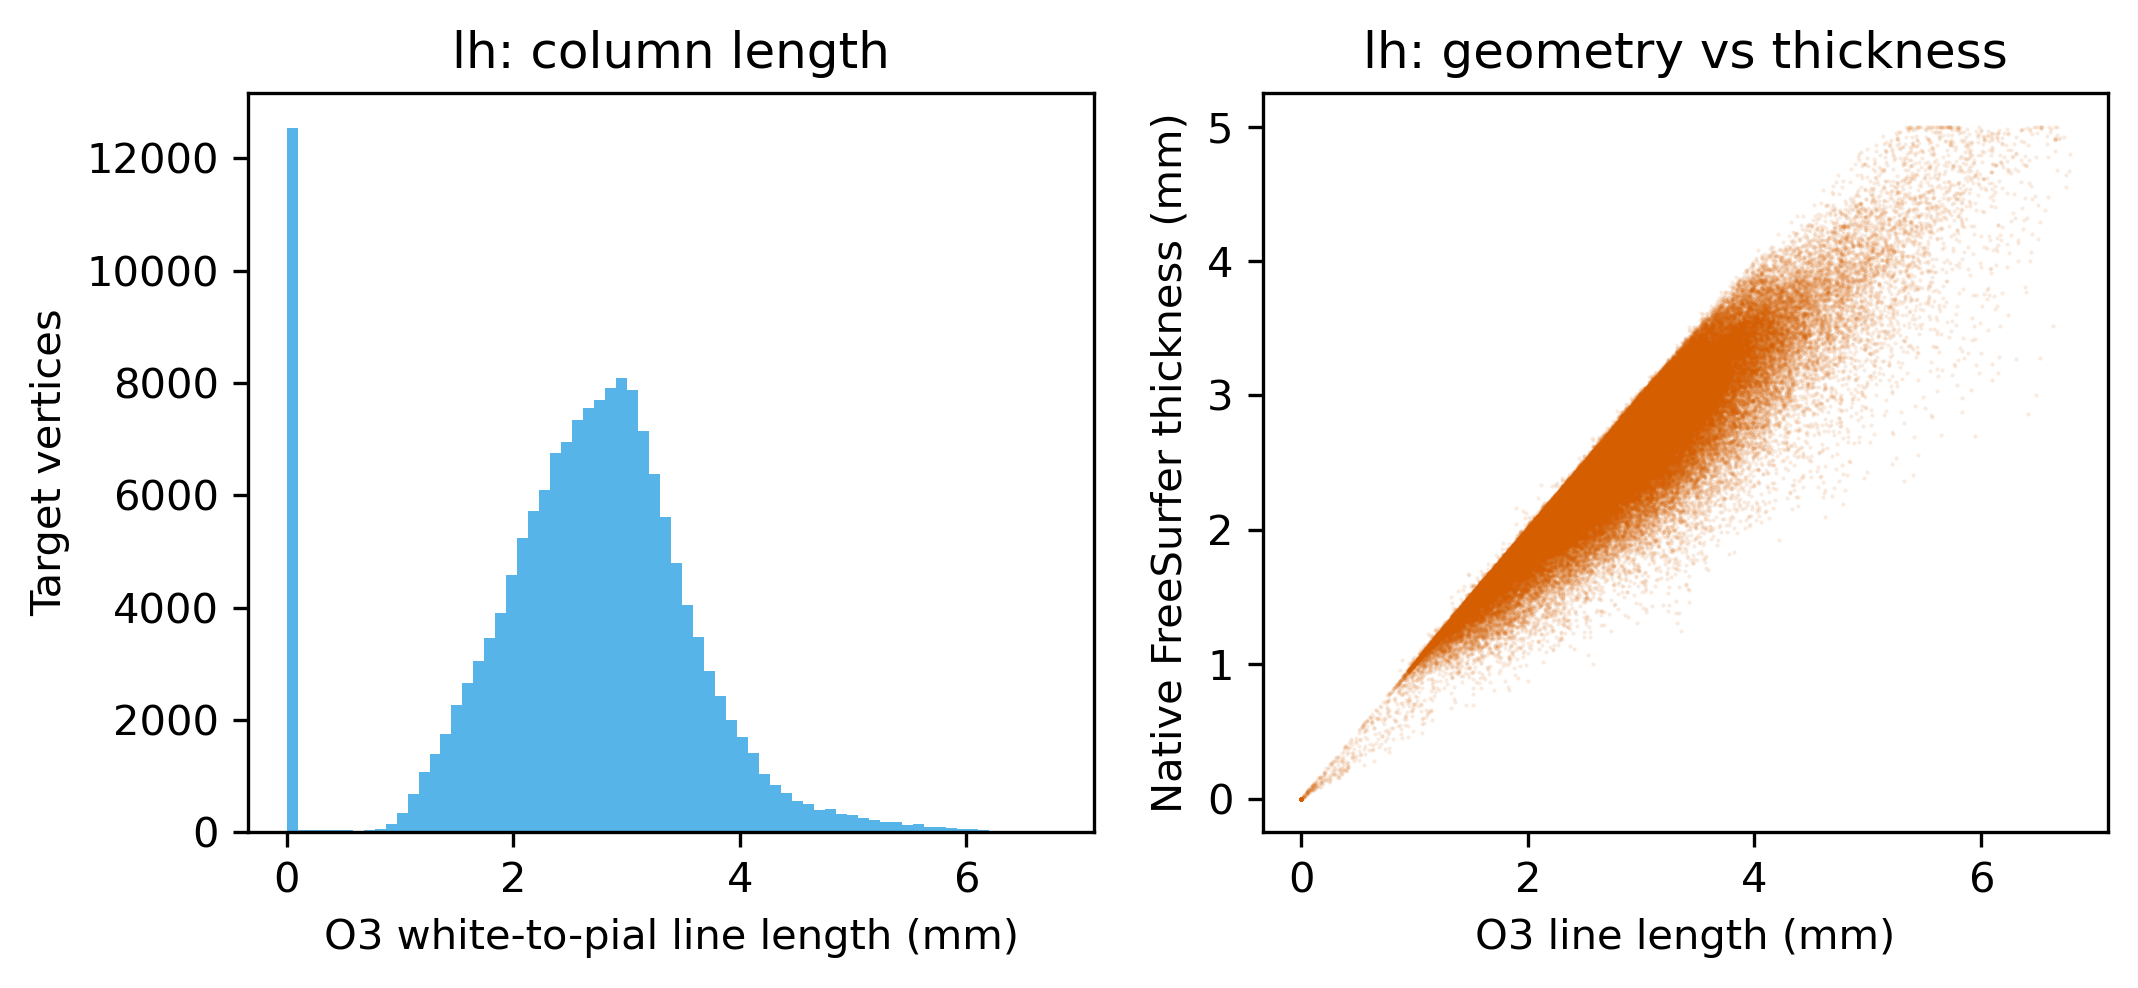

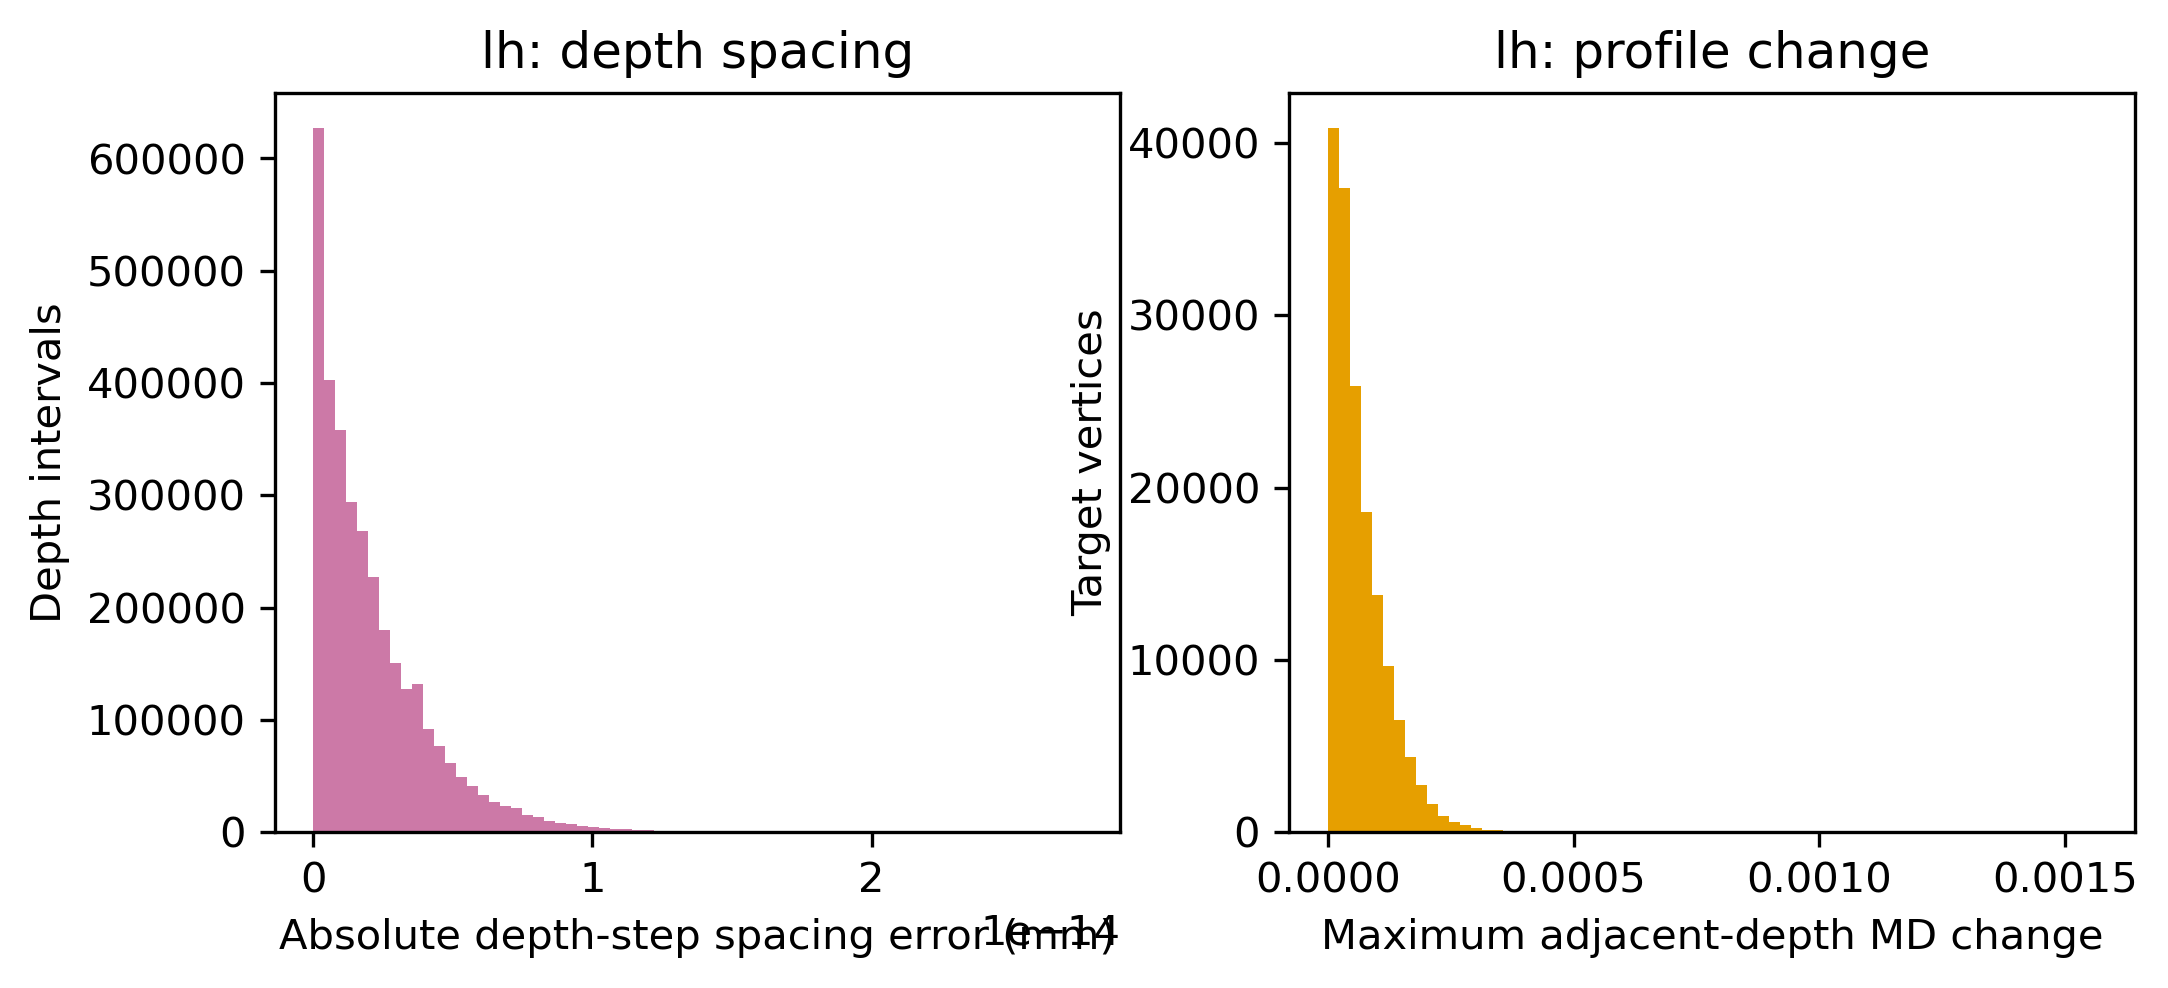

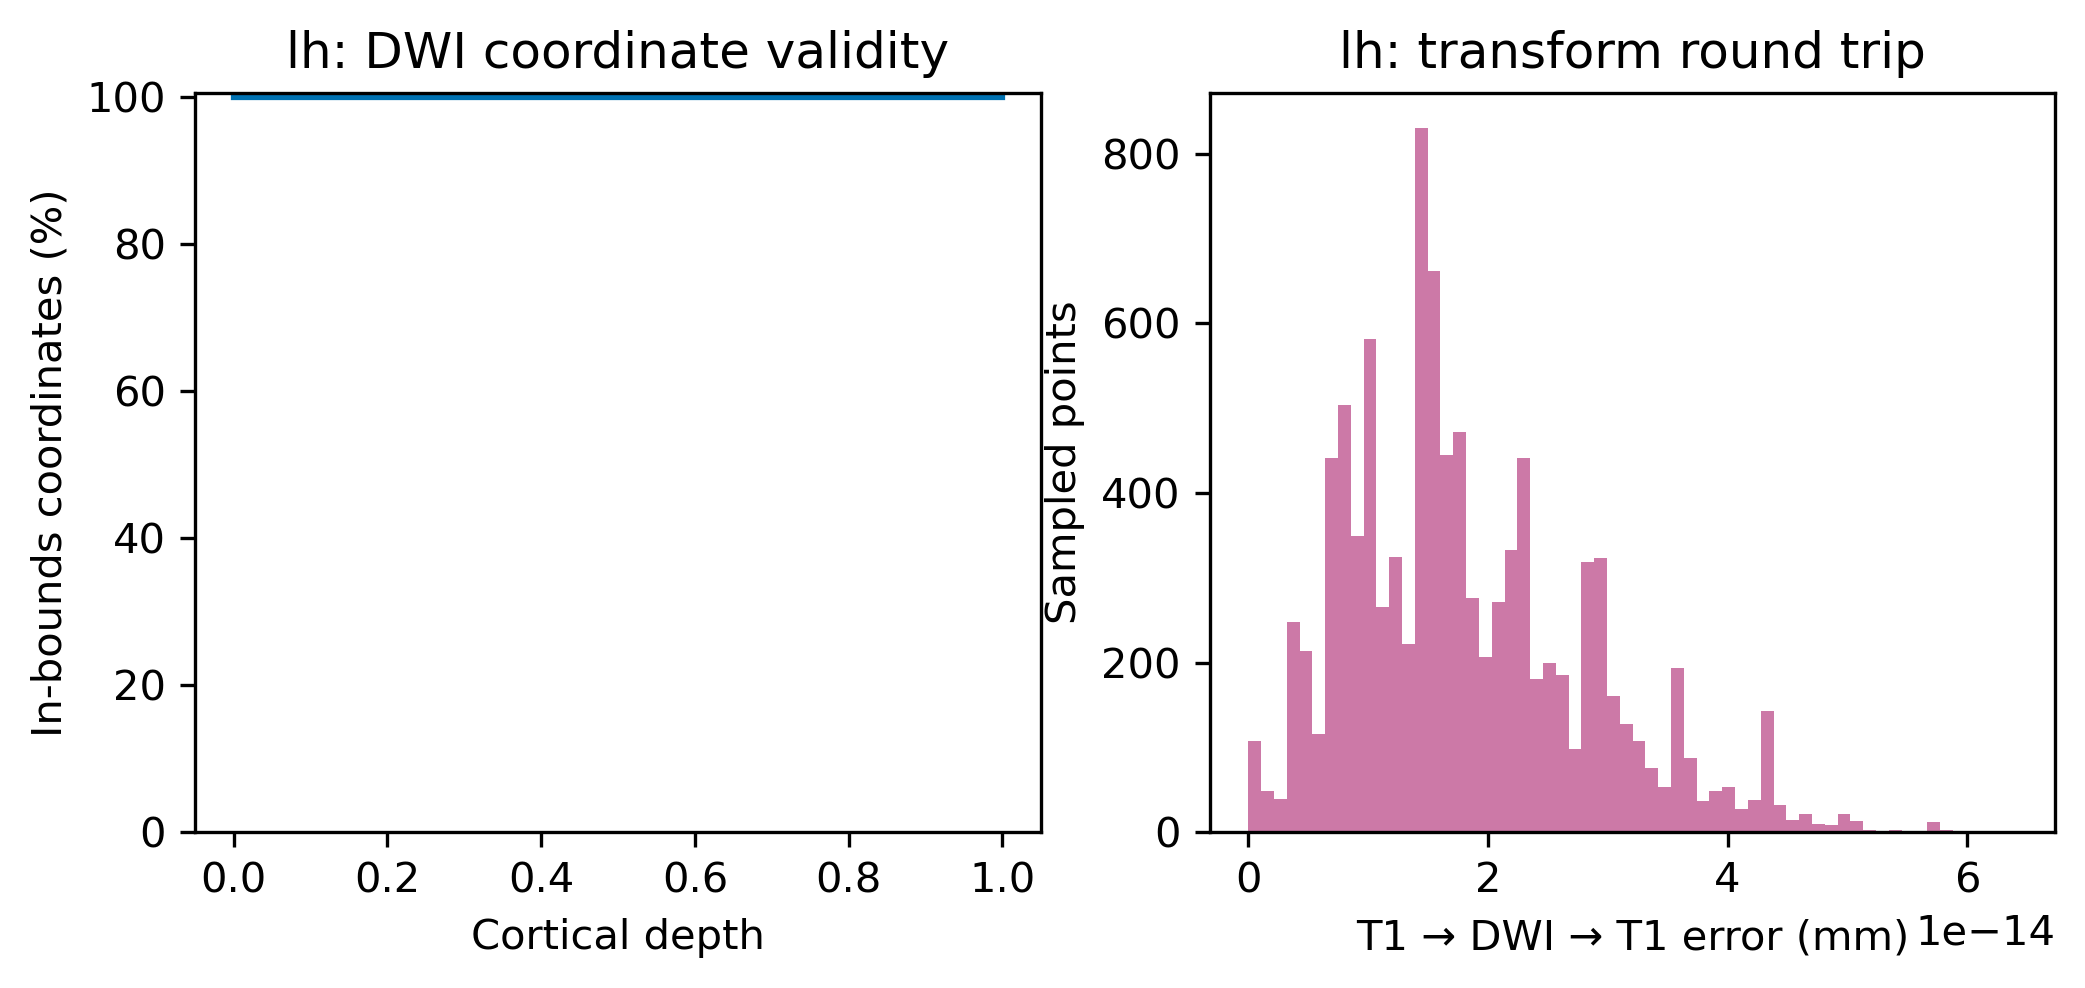

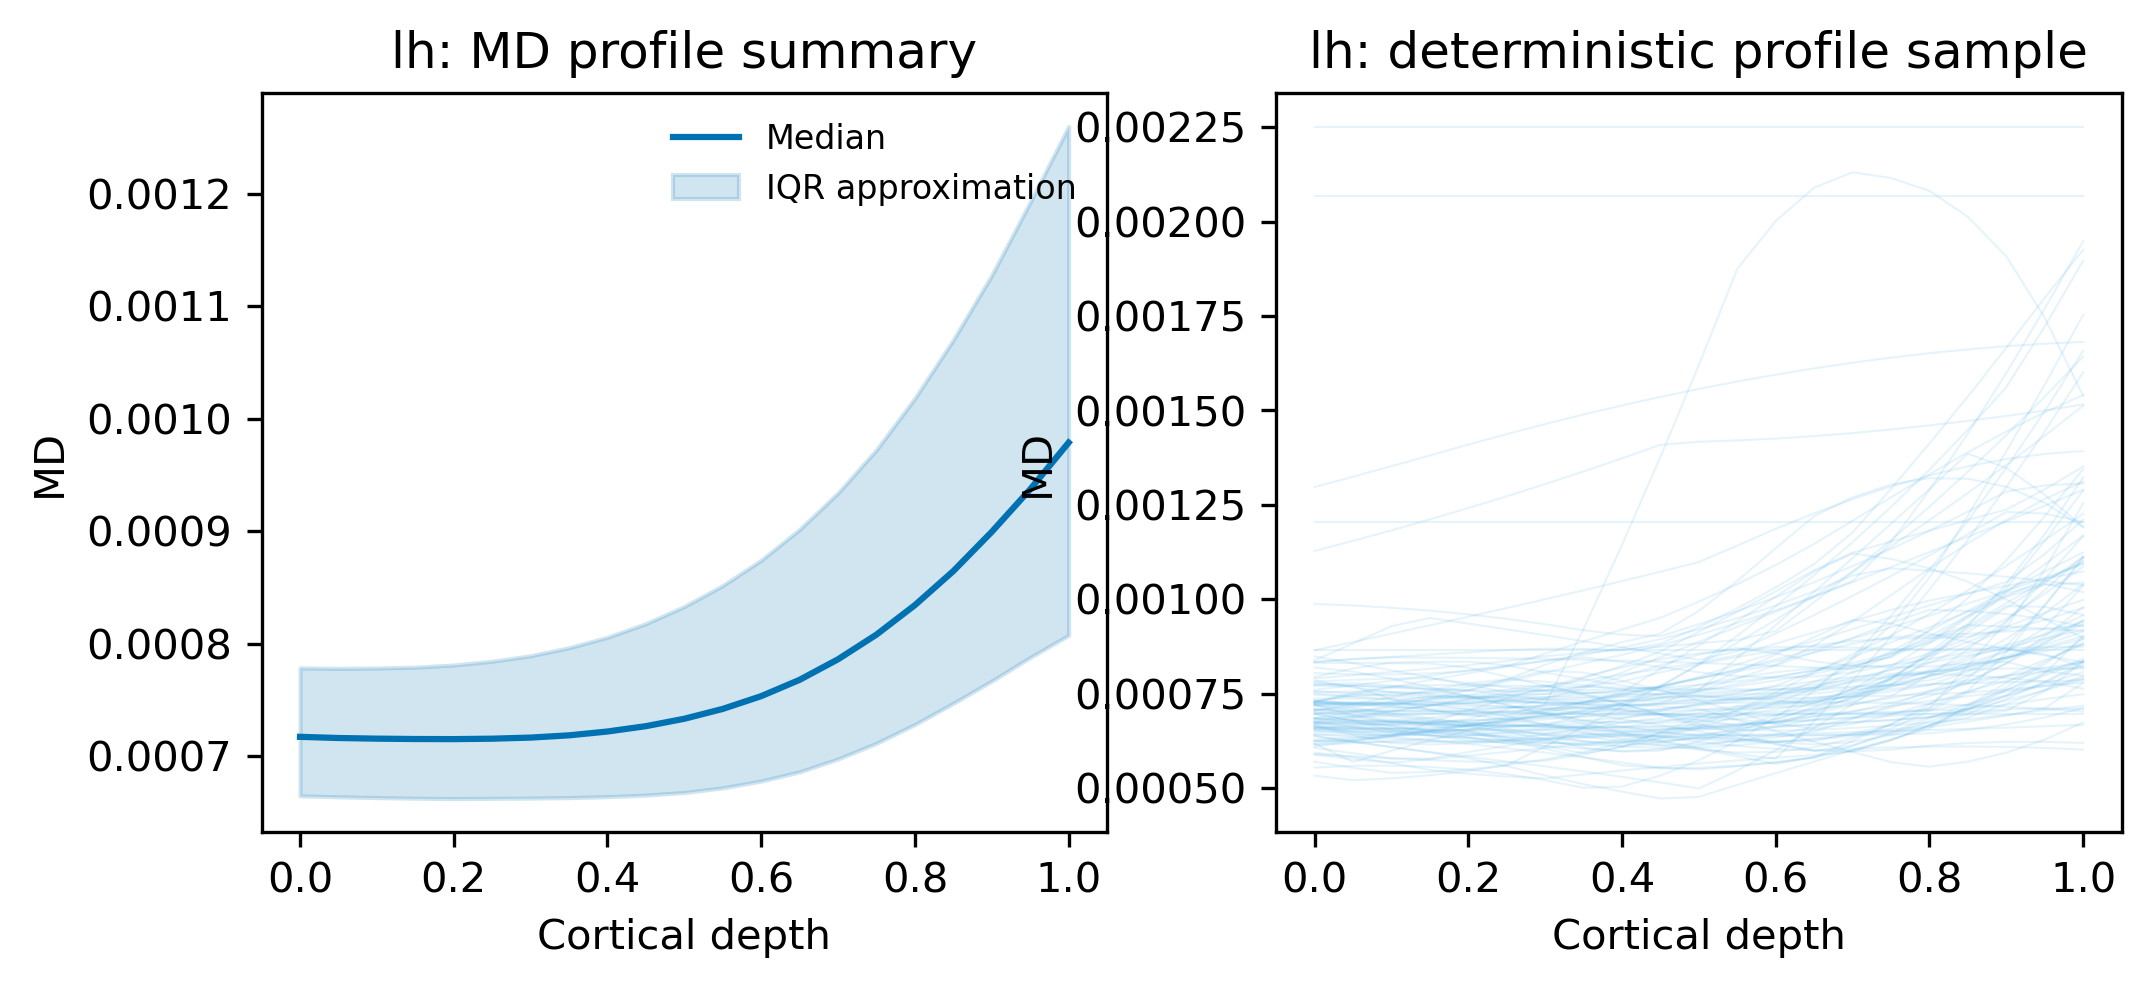

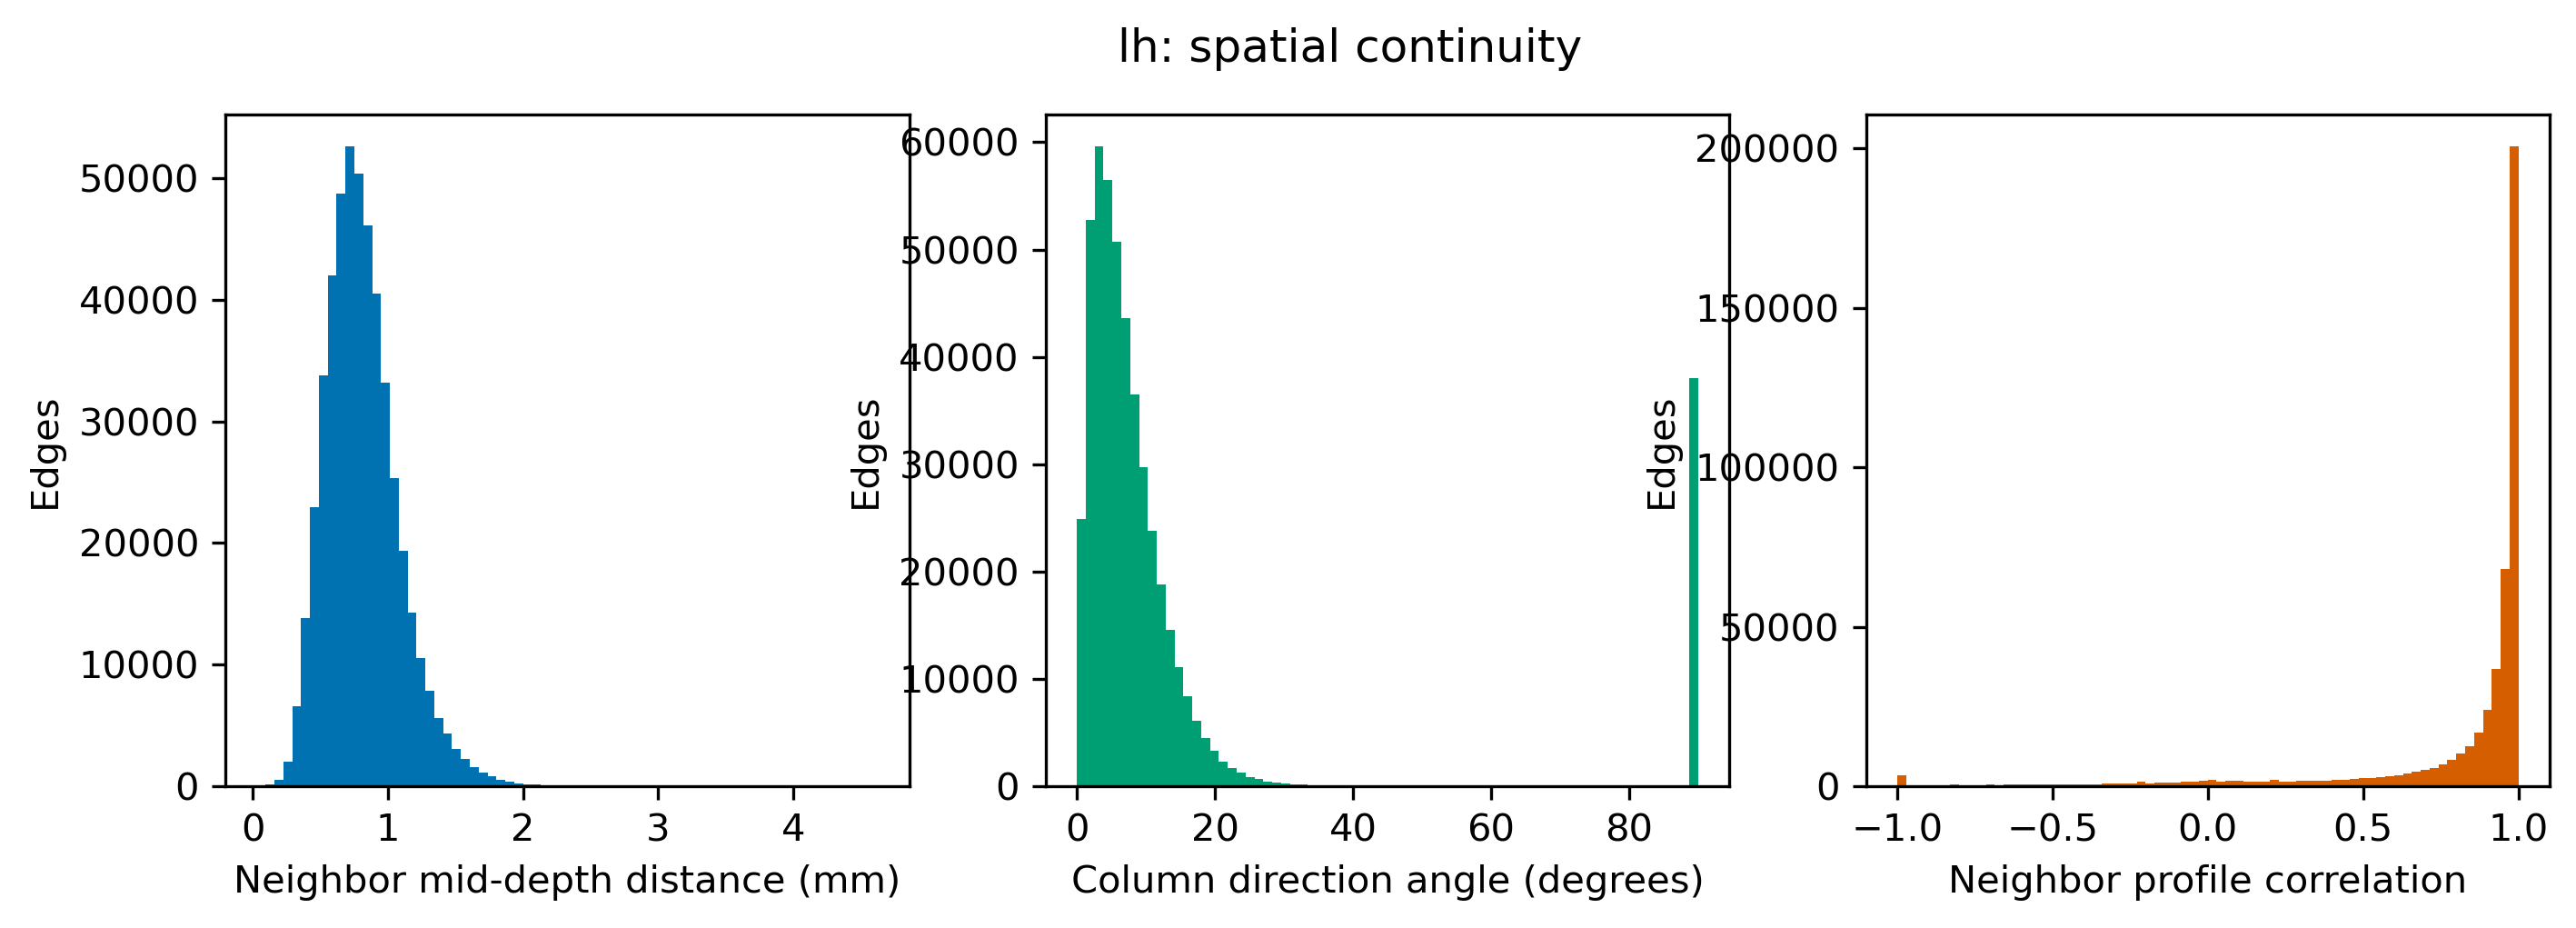

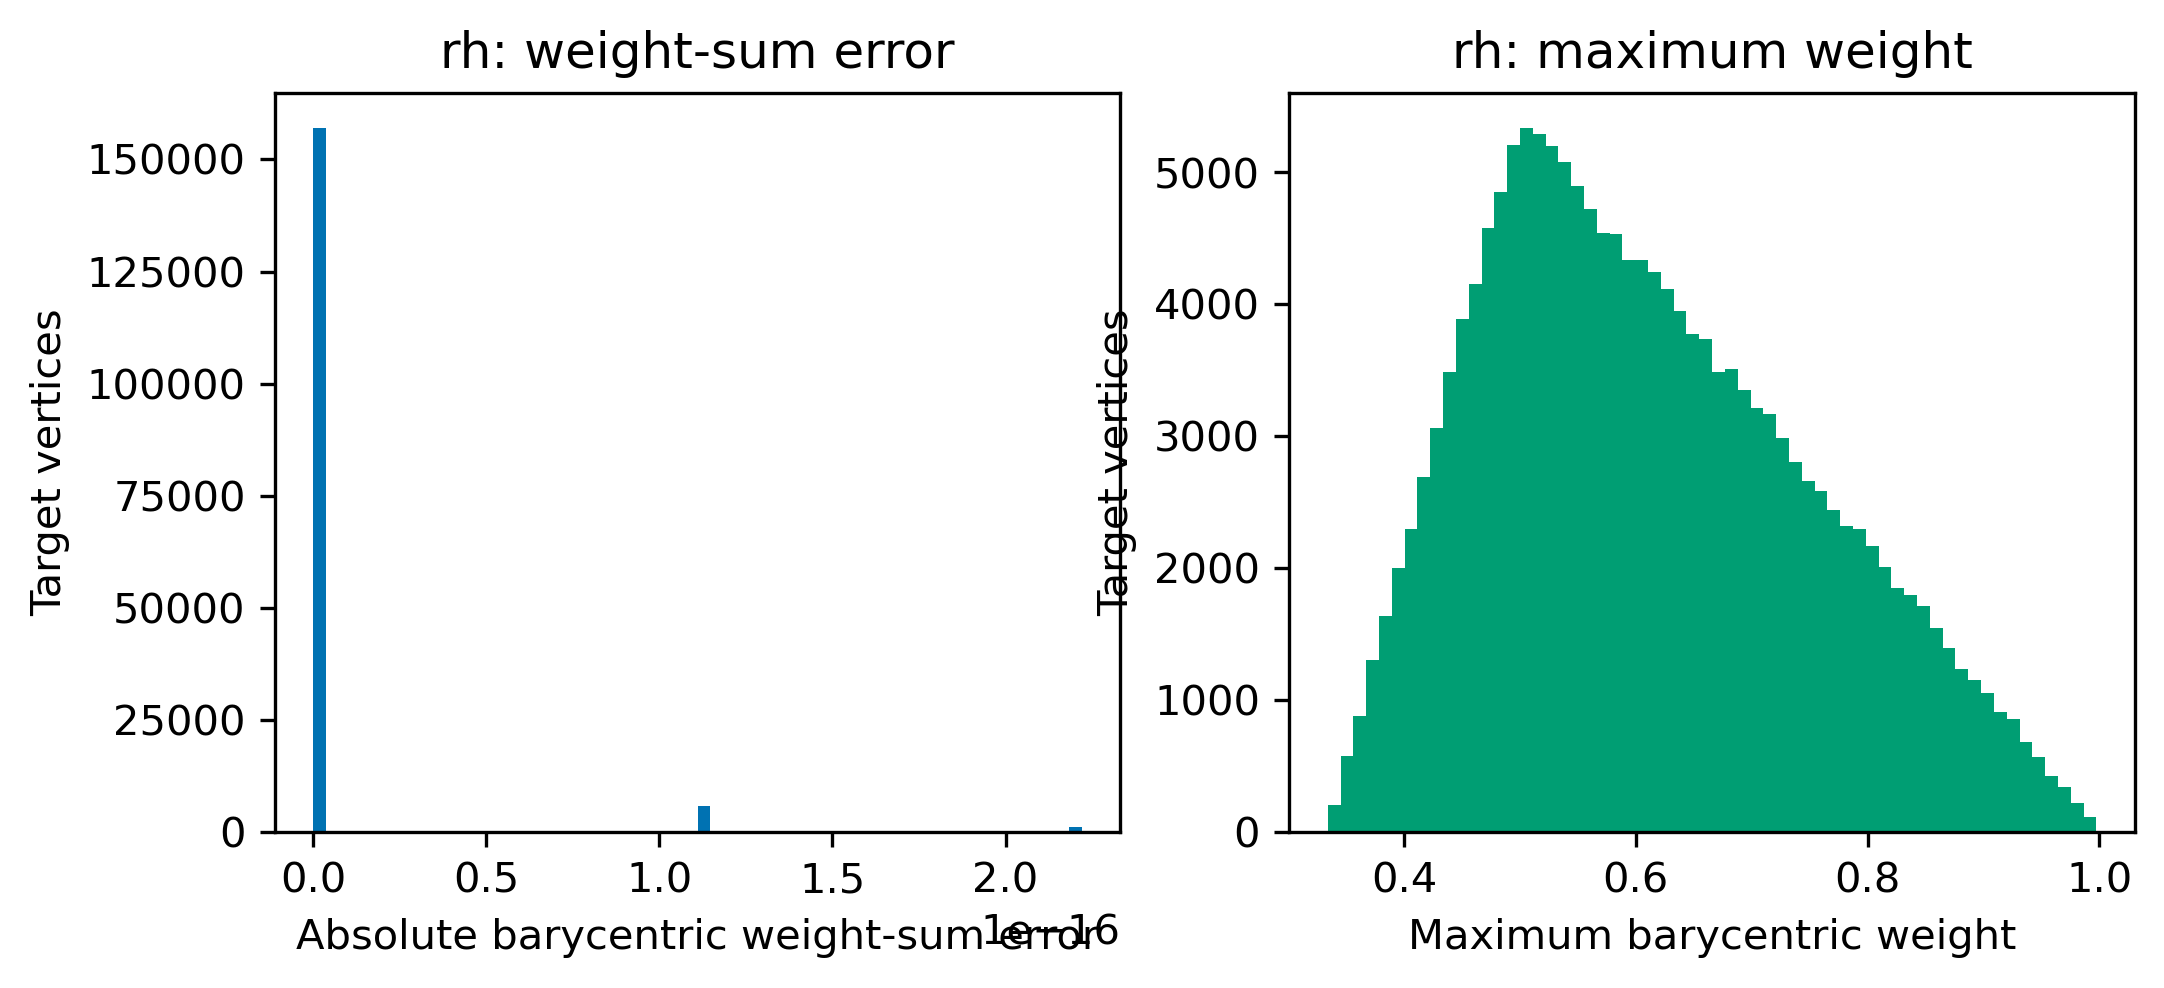

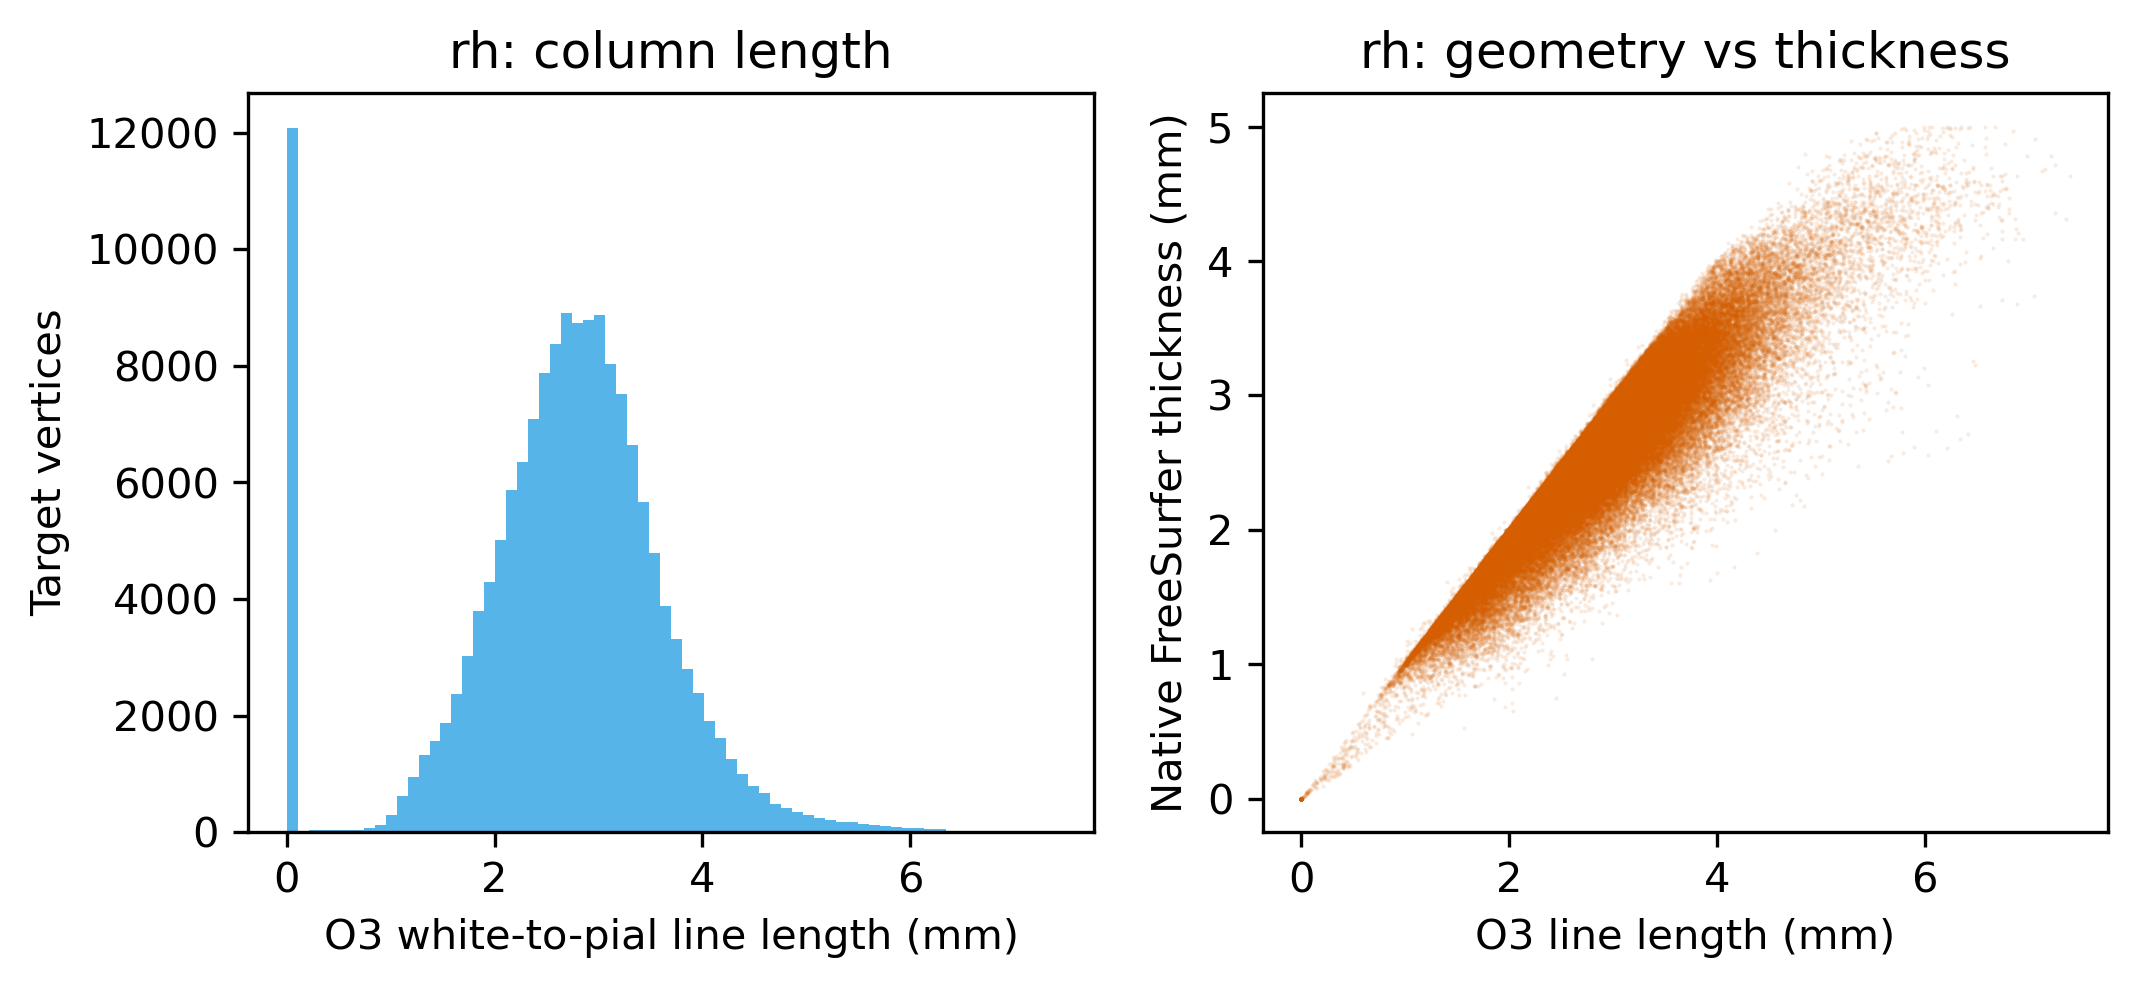

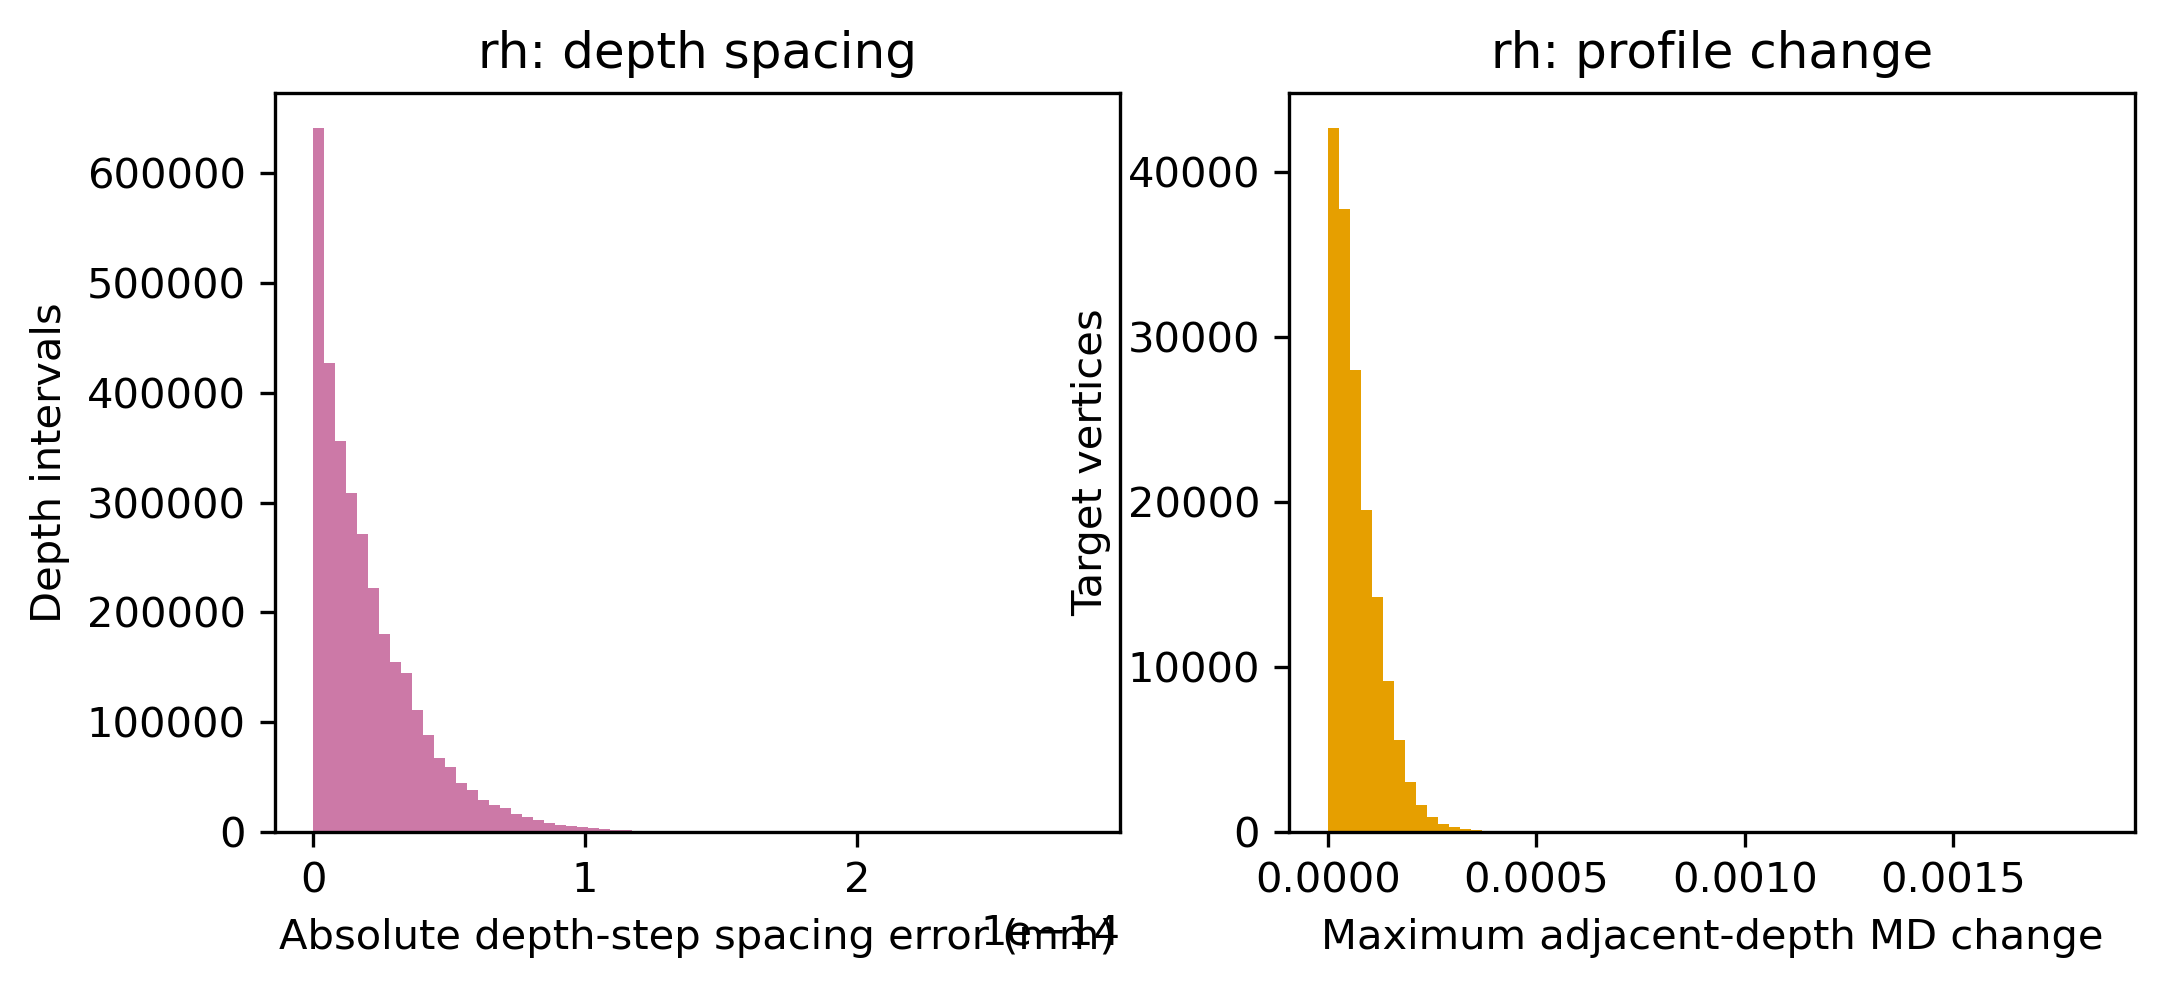

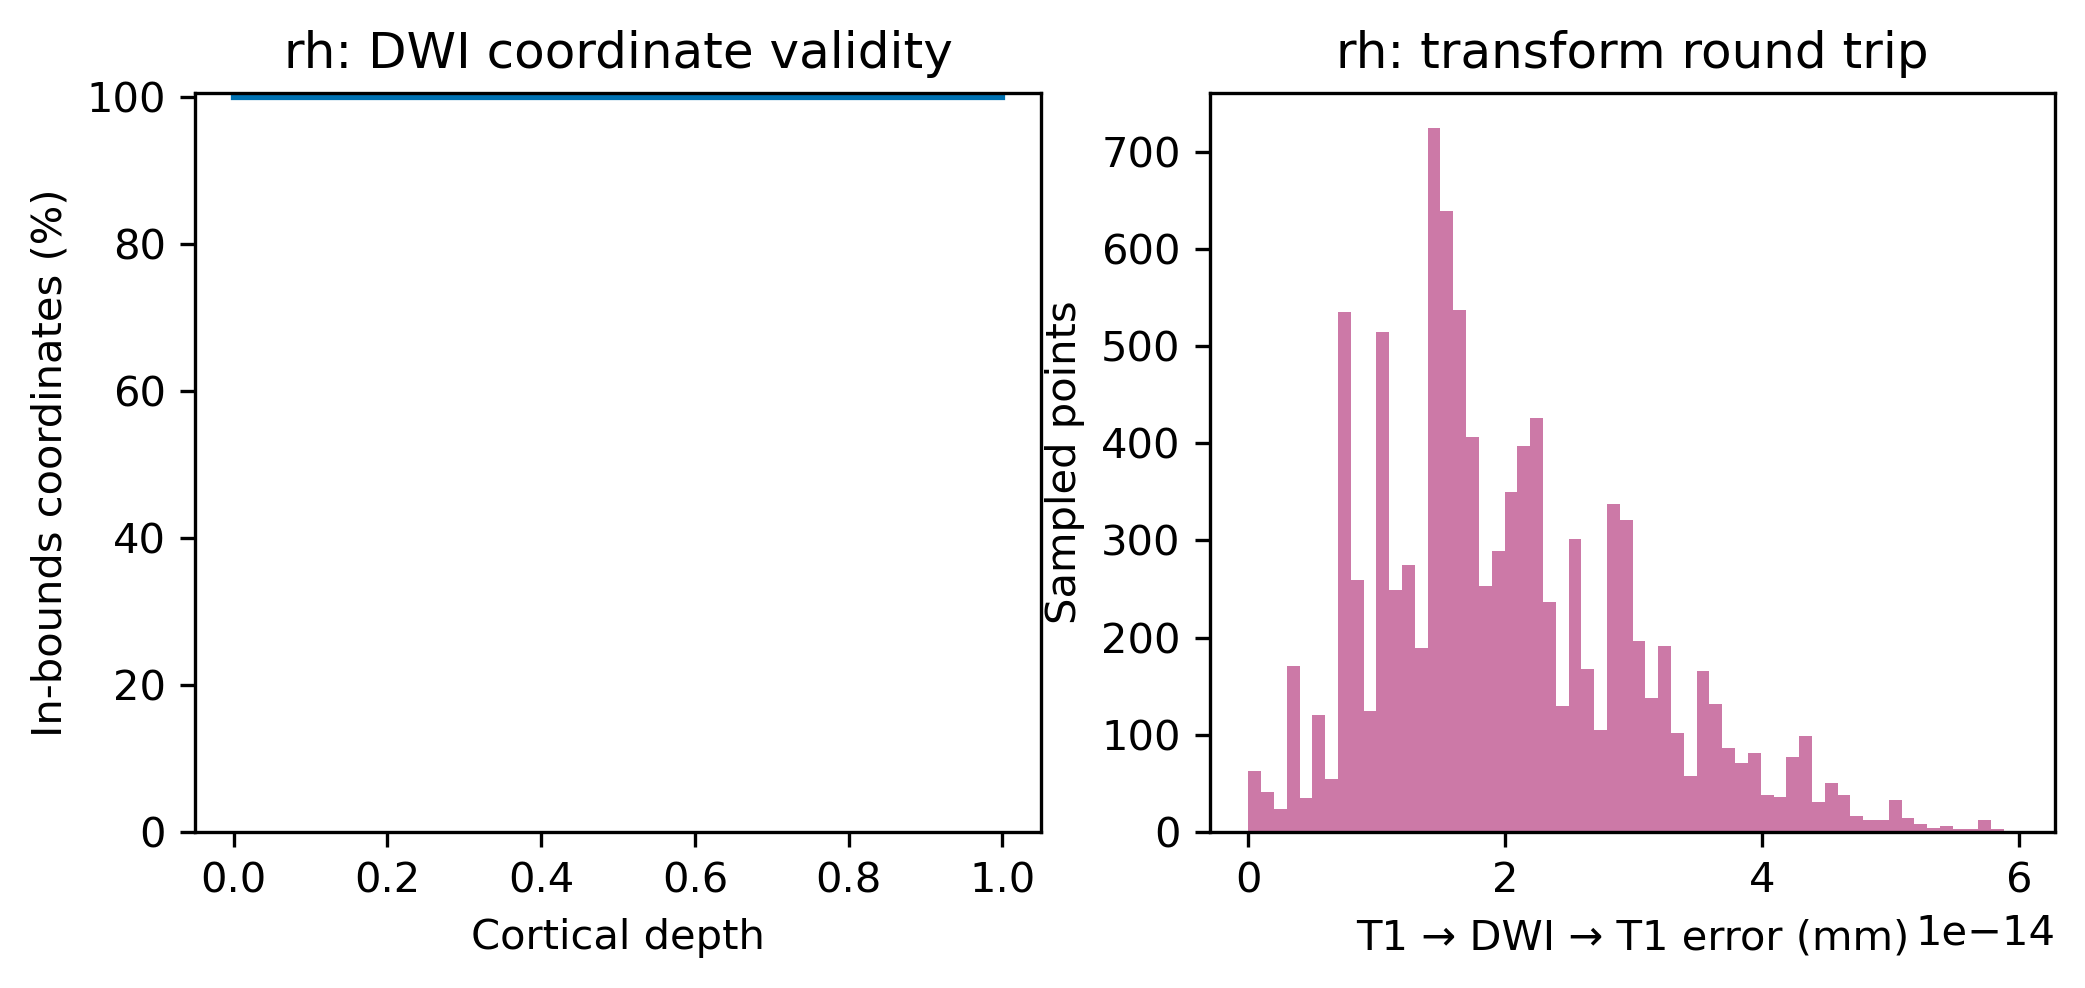

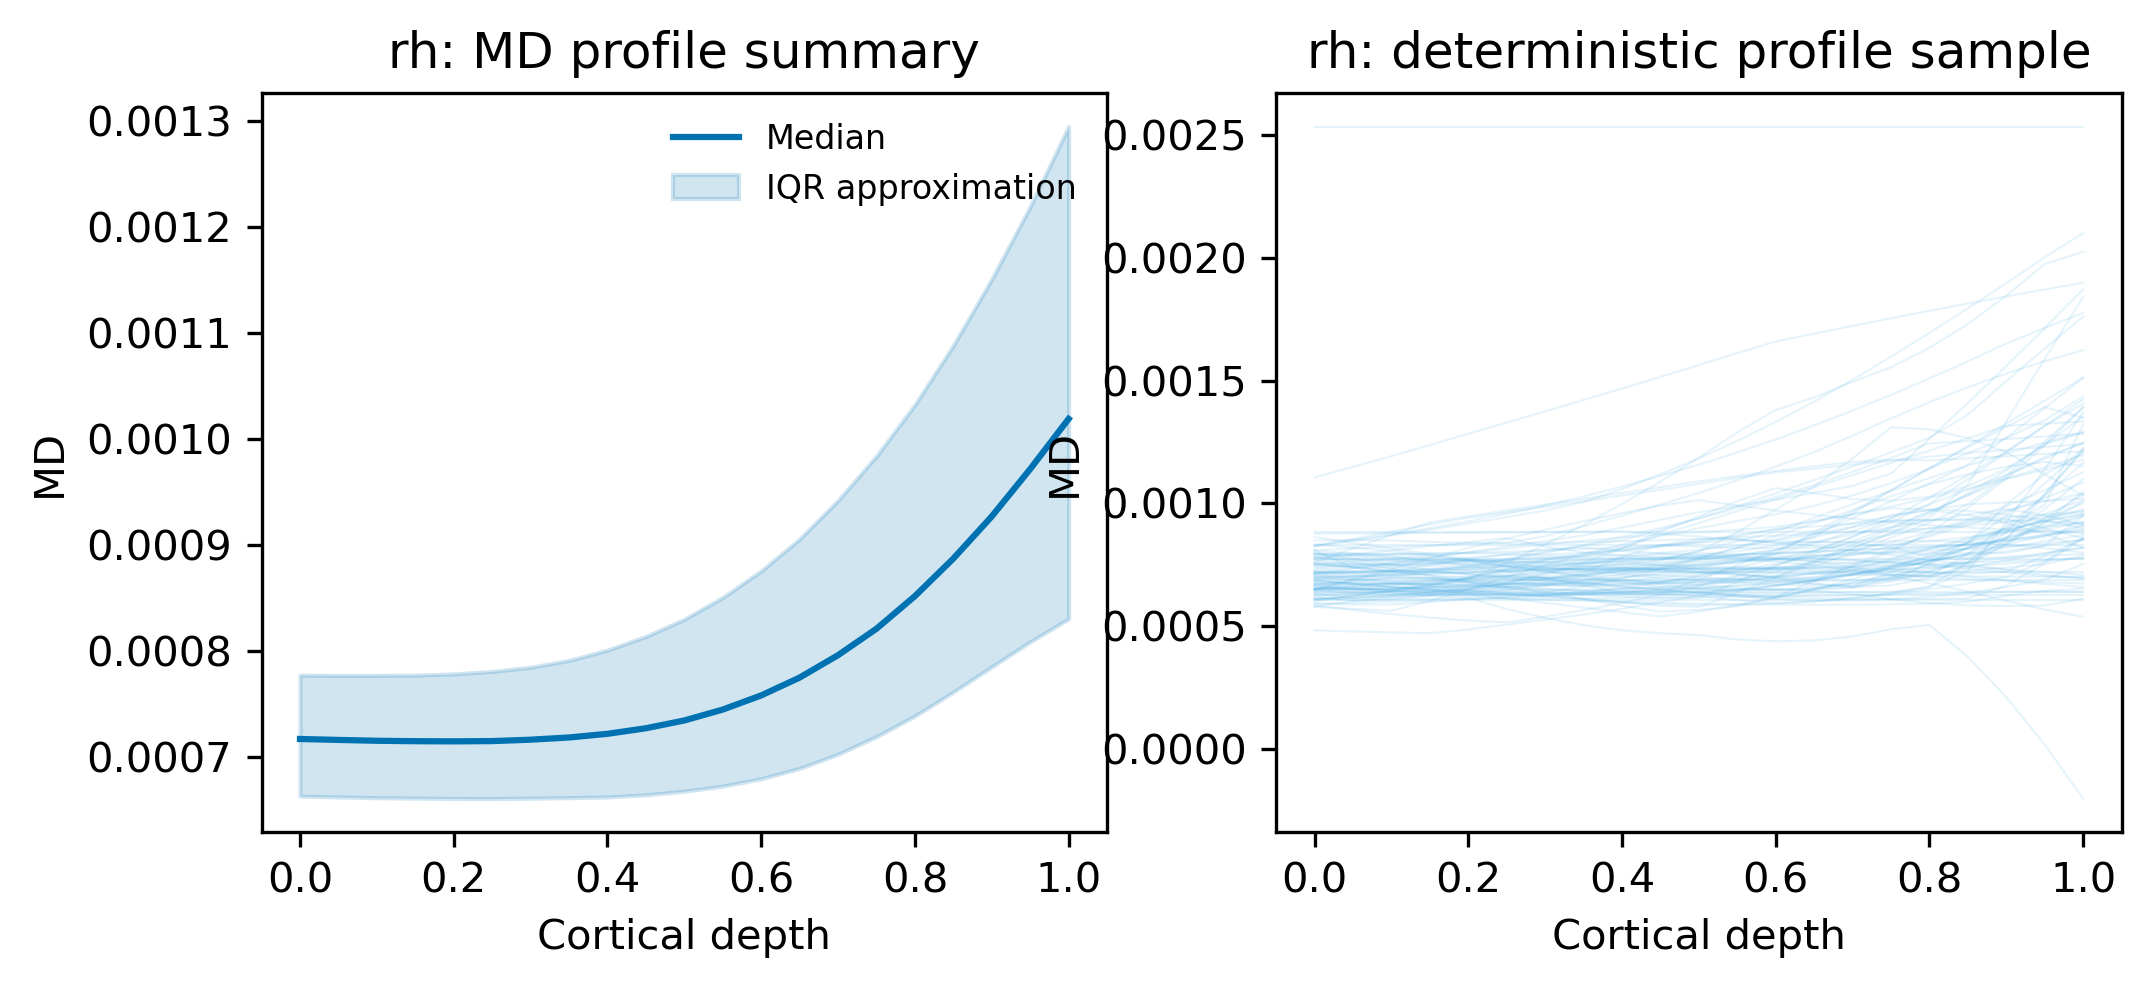

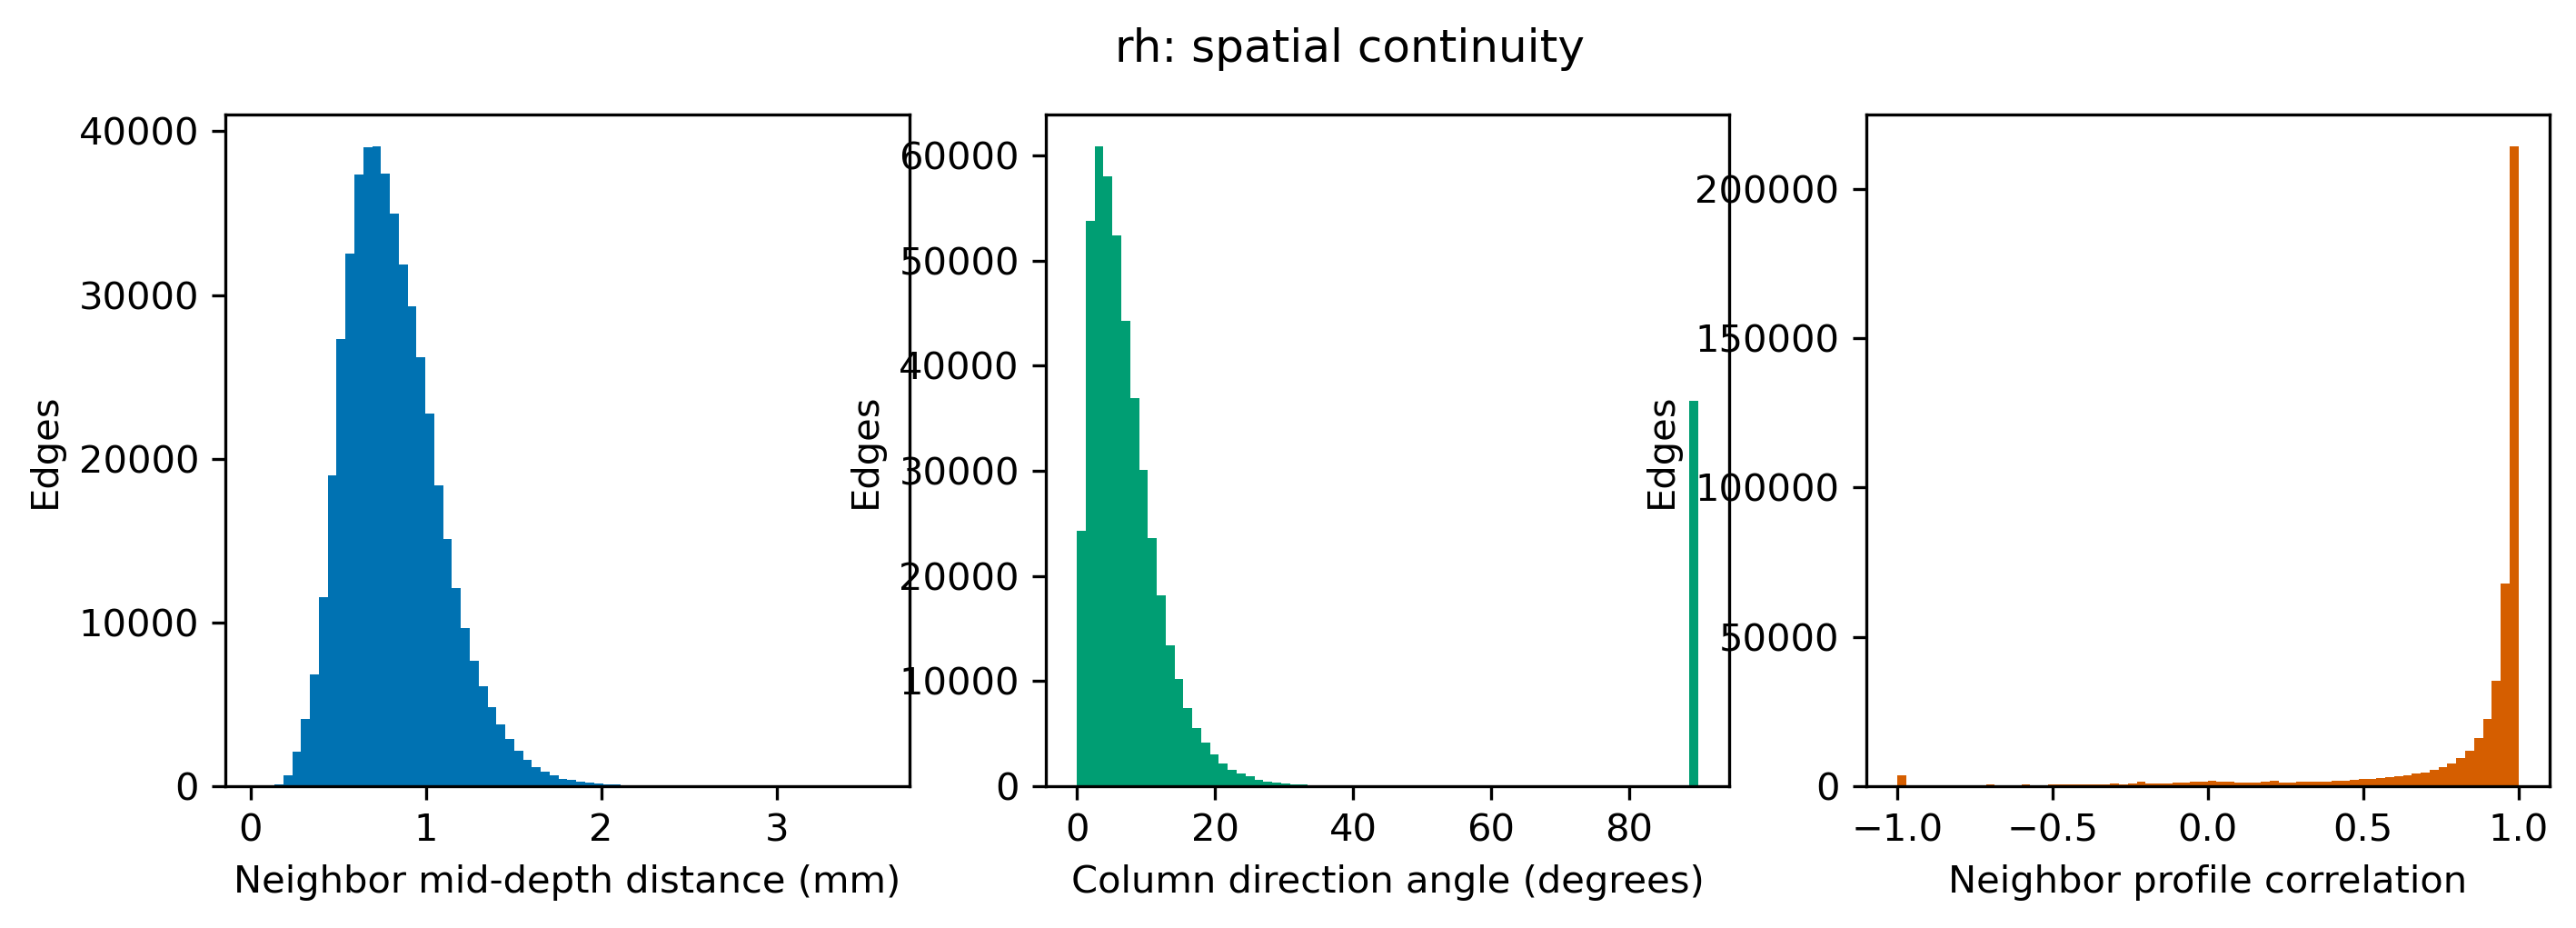

,Freeview_overlay
0,/mnt/newStor/paros/paros_WORK/xintong/results/...
1,/mnt/newStor/paros/paros_WORK/xintong/results/...
2,/mnt/newStor/paros/paros_WORK/xintong/results/...
3,/mnt/newStor/paros/paros_WORK/xintong/results/...
4,/mnt/newStor/paros/paros_WORK/xintong/results/...
5,/mnt/newStor/paros/paros_WORK/xintong/results/...
6,/mnt/newStor/paros/paros_WORK/xintong/results/...
7,/mnt/newStor/paros/paros_WORK/xintong/results/...


In [5]:
figure_paths = sorted((output_root / "figures").glob("*.png"))
for figure_path in figure_paths:
    display(Image(filename=str(figure_path), width=900))

overlay_paths = sorted((output_root / "overlays").glob("*.mgh"))
display(
    pd.DataFrame(
        {"Freeview_overlay": [str(path) for path in overlay_paths]}
    )
)

## Final interpretation rule

PASS/FAIL checks use the configured completeness, weight, coordinate,
and profile thresholds. Mixed-label triangles and robust column-length
outliers are descriptive warnings only; they are retained for
sensitivity analysis and are not automatically removed.